# Proyecto RappiPlus: de datos a decisiones de negocio

**Introducción**

El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabajan con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python)

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.


## 🔹 Paso 1: Carga y validación de la calidad de los datos


In [2]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from statsmodels.stats.proportion import proportions_ztest
from dotenv import load_dotenv
import os

In [3]:
#Se evitó poner la ruta de forma explícita.
load_dotenv()
ordersDataset=os.getenv("ORDERSPATH")
catalogDataset=os.getenv("CATALOGPATH")
marketingDataset=os.getenv("MARKETINGPATH")

In [4]:
# cargar archivos
orders = pd.read_csv(ordersDataset)
catalog = pd.read_csv(catalogDataset)
marketing = pd.read_csv(marketingDataset)

In [5]:
# explorar datasets
print("dataset orders:")
print(orders.head())
print()
print("dataset catalog:")
print(catalog.head())
print()
print("dataset marketing:")
print(marketing.head())


dataset orders:
  id_pedido id_usuario fecha_hora_pedido       pais dispositivo  \
0   order_0  user_6993        2025-05-22  Argentina     desktop   
1   order_1  user_1329        2025-06-15     Mexico     desktop   
2   order_2  user_3194        2025-05-02  Argentina     desktop   
3   order_3  user_4510        2025-06-09   Colombia      mobile   
4   order_4  user_5044        2025-03-30  Argentina     desktop   

  fuente_referencia       nombre_producto categoria_producto  cantidad  \
0           organic       Jacket-Winter-M               Moda       2.0   
1       paid_search  Tablet-Standard-64GB        Electronica       1.0   
2            social        Blender-XL-Red              Hogar       2.0   
3            social  Tablet-Standard-64GB        Electronica       1.0   
4       paid_search        Blender-XL-Red              Hogar       1.0   

   precio_unitario  monto_descuento  monto_total  
0           332.69              0.0       665.37  
1           176.86              5.

In [6]:
# Revisamos datatypes de orders

orders.info()


<class 'pandas.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  str    
 1   id_usuario          25100 non-null  str    
 2   fecha_hora_pedido   25100 non-null  str    
 3   pais                24800 non-null  str    
 4   dispositivo         25080 non-null  str    
 5   fuente_referencia   25070 non-null  str    
 6   nombre_producto     25070 non-null  str    
 7   categoria_producto  25020 non-null  str    
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), str(8)
memory usage: 2.3 MB


In [7]:
#Inspección de estadísticas descriptivas del dataset orders
print("\033[1mDescripciones númericas\033[0m")
print(orders.describe())
print()
print("\033[1mDescripciones de los tipos string/objects\033[0m")
print(orders.describe(include=["str"]))

Descripciones númericas
           cantidad  precio_unitario  monto_descuento   monto_total
count  25050.000000     25050.000000     25050.000000  2.510000e+04
mean       7.092735       259.305549         4.500798  2.072680e+03
std      296.277003       138.726461         5.223010  9.894995e+04
min       -2.000000        20.030000         0.000000 -4.926500e+02
25%        1.000000       138.377500         0.000000  1.805075e+02
50%        2.000000       258.715000         0.000000  3.417500e+02
75%        2.000000       380.332500        10.000000  5.185800e+02
max    20000.000000       499.960000        15.000000  8.840200e+06

Descripciones de los tipos string/objects
        id_pedido id_usuario fecha_hora_pedido      pais dispositivo  \
count       25100      25100             25100     24800       25080   
unique      25000       7642               181         6           2   
top     order_734  user_7769        2025-06-25  Colombia     desktop   
freq            2         11     

In [8]:
#Hay señales de valores ausentes por incordancias en los conteos.
orders.isna().sum() #Vemos como concuerdan los conteos al considerar la suma de valores ausentes por columna.

id_pedido               0
id_usuario              0
fecha_hora_pedido       0
pais                  300
dispositivo            20
fuente_referencia      30
nombre_producto        30
categoria_producto     80
cantidad               50
precio_unitario        50
monto_descuento        50
monto_total             0
dtype: int64

In [9]:
# Revisamos el valor mínimo en la cantidad y vemos si ese valor mínimo es poco plausible y si
# esta asociado al valor mínimo inválido del monto total.
orders[orders['cantidad']==-2] # No están asociados esos números.


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
266,order_266,user_7011,2025-03-13,NaN,desktop,paid_search,Phone-Pro-128GB,Electronica,-2.0,101.31,10.0,-192.62


In [10]:
#Pero seguro hay otra cantidad negativa asociada a ese monto total mínimo
orders[orders['monto_total']==-492.65]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
268,order_268,user_84,2025-02-19,NaN,desktop,organic,Phone-Pro-128GB,Electronica,-1.0,497.65,5.0,-492.65


In [11]:
#Inspeccionamos posibles clientes por mayoreo
orders[orders['monto_total']>=1000000] # se ven bien y congruentes

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
3522,order_3522,user_3575,2025-03-29,Argentina,desktop,social,Laptop-Gaming-16GB,Electronica,10000.0,280.55,0.0,2805500.0
3586,order_3586,user_3380,2025-02-03,Mexico,mobile,paid_search,Laptop-Gaming-16GB,Electronica,10000.0,490.35,0.0,4903500.0
3643,order_3643,user_4440,2025-01-07,Colombia,desktop,social,Laptop-Gaming-16GB,Electronica,10000.0,238.15,0.0,2381500.0
3656,order_3656,user_884,2025-01-01,Argentina,mobile,organic,Laptop-Gaming-16GB,Electronica,20000.0,297.66,0.0,5953200.0
3668,order_3668,user_7270,2025-06-24,Mexico,mobile,paid_search,Laptop-Gaming-16GB,Electronica,20000.0,348.31,0.0,6966200.0
3722,order_3722,user_4723,2025-05-09,Argentina,mobile,paid_search,Laptop-Gaming-16GB,Electronica,20000.0,442.01,0.0,8840200.0
3726,order_3726,user_2536,2025-02-12,Colombia,desktop,social,Laptop-Gaming-16GB,Electronica,20000.0,290.85,0.0,5817000.0
3748,order_3748,user_7096,2025-02-23,Mexico,desktop,organic,Laptop-Gaming-16GB,Electronica,10000.0,336.93,0.0,3369300.0


In [12]:
#Información general de limpieza del dataset orders
atributos=['id_pedido','id_usuario','fecha_hora_pedido','pais','dispositivo','fuente_referencia', 'nombre_producto','categoria_producto','cantidad', 'precio_unitario','monto_descuento']
print("\033[1mCifras de referencia del dataset --orders-- crudo:\033[0m") #Formateo de negritas con ANSI \033[1m y \033[0m
print("número de instancias(filas) totales del dataset crudo: "+str(orders.shape[0]))
numero_istancias_crudo=orders.shape[0]
print("ingreso total con dataset crudo: "+ "$"+str(orders['monto_total'].sum()))
ingreso_crudo=orders['monto_total'].sum()
print()
print("\033[1mCifras de impacto al evaluar estrategia de limpieza por complete case analysis(removemos filas con valores ausentes):\033[0m") #Formateo de negritas con ANSI \033[1m y \033[0m
print("número de instancias(filas) con valores ausentes: "+ str(orders.isna().any(axis=1).sum()))
print("porcentaje de pérdida de información: "+str(orders.isna().any(axis=1).mean()*100)+"%")
print("pérdida de ingreso por pérdida de información: "+ "$"+str(orders[orders[atributos].isna().any(axis=1)]['monto_total'].sum()))
print("porcentaje de pérdida de ingreso por pérdida de información: "+str((orders[orders[atributos].isna().any(axis=1)]['monto_total'].sum()/ orders['monto_total'].sum())*100)+"%")

print()
print("\033[1mResultado remanente del dataset --orders-- limpio de valores ausentes:\033[0m") #Formateo de negritas con ANSI \033[1m y \033[0m
print("número de instancias(filas) totales del dataset limpio: "+str(orders.shape[0]-orders.isna().any(axis=1).sum()))
print("ingreso total con dataset limpio: "+ "$"+str(orders['monto_total'].sum()-orders[orders[atributos].isna().any(axis=1)]['monto_total'].sum()))
# DECISIÓN DE LIMPIEZA - Complete Case Analysis:
# Se aplica Complete Case Analysis (1.59% de datos eliminados).
# Impacto financiero marginal (0.29% ingresos), evitando el costo operativo
# e incertidumbre de imputar variables con posible patrón MNAR.

Cifras de referencia del dataset --orders-- crudo:
número de instancias(filas) totales del dataset crudo: 25100
ingreso total con dataset crudo: $52024257.55999999

Cifras de impacto al evaluar estrategia de limpieza por complete case analysis(removemos filas con valores ausentes):
número de instancias(filas) con valores ausentes: 400
porcentaje de pérdida de información: 1.593625498007968%
pérdida de ingreso por pérdida de información: $151087.12
porcentaje de pérdida de ingreso por pérdida de información: 0.29041667692374085%

Resultado remanente del dataset --orders-- limpio de valores ausentes:
número de instancias(filas) totales del dataset limpio: 24700
ingreso total con dataset limpio: $51873170.43999999


In [13]:
#Inspección de valores duplicados
#Las llaves primarias debieran ser únicas y no visualizamos eso en la estadística descriptiva entre los conteos y los valores únicos.
#Certificamos la presencia de duplicados
print(f'número de ids duplicadas: {orders["id_pedido"].duplicated().sum()}') #Los números coinciden se deben a duplicados
#Las filas u ordenes duplicadas coinciden con el valor de las ids de pedido duplicadas?
print(f'número de ordenes duplicadas: {orders.duplicated().sum()}') # Sí



número de ids duplicadas: 100
número de ordenes duplicadas: 100


In [14]:
#Inspección de valores únicos de valores categóricos
atributos_categoricos=['pais','dispositivo','fuente_referencia', 'nombre_producto','categoria_producto']
for atributo in atributos_categoricos:
    print (f'valores únicos en {atributo}: {orders[atributo].unique()}') #Vemos errores de validación de valores

valores únicos en pais: <StringArray>
['Argentina', 'Mexico', 'Colombia', 'mexico', 'colombia', 'argentina', nan]
Length: 7, dtype: str
valores únicos en dispositivo: <StringArray>
['desktop', 'mobile', nan]
Length: 3, dtype: str
valores únicos en fuente_referencia: <StringArray>
['organic', 'paid_search', 'social', nan]
Length: 4, dtype: str
valores únicos en nombre_producto: <StringArray>
[     'Jacket-Winter-M', 'Tablet-Standard-64GB',       'Blender-XL-Red',
   'Laptop-Gaming-16GB',    'Sneakers-Urban-42',      'Phone-Pro-128GB',
     'Vacuum-Pro-Black',                    nan]
Length: 8, dtype: str
valores únicos en categoria_producto: <StringArray>
['Moda', 'Electronica', 'Hogar', nan]
Length: 4, dtype: str


In [15]:
#Inspección de fechas

fechas_convertidas = pd.to_datetime(orders["fecha_hora_pedido"], errors="coerce")
validas = fechas_convertidas.notna().sum()
total = orders["fecha_hora_pedido"].shape[0]

print(f"{validas} fechas convertibles de {total} fechas esperadas")

25100 fechas convertibles de 25100 fechas esperadas


In [16]:
#Correciones
#Lidiando con los NA (Los eliminamos)
orders=orders.dropna()
orders.shape[0] # Obtenemos lo esperado

24700

In [17]:
#Lidiando con tipo de datos
orders['fecha_hora_pedido']= pd.to_datetime(orders["fecha_hora_pedido"], errors="coerce")
orders.info()


<class 'pandas.DataFrame'>
Index: 24700 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           24700 non-null  str           
 1   id_usuario          24700 non-null  str           
 2   fecha_hora_pedido   24700 non-null  datetime64[us]
 3   pais                24700 non-null  str           
 4   dispositivo         24700 non-null  str           
 5   fuente_referencia   24700 non-null  str           
 6   nombre_producto     24700 non-null  str           
 7   categoria_producto  24700 non-null  str           
 8   cantidad            24700 non-null  float64       
 9   precio_unitario     24700 non-null  float64       
 10  monto_descuento     24700 non-null  float64       
 11  monto_total         24700 non-null  float64       
dtypes: datetime64[us](1), float64(4), str(7)
memory usage: 2.4 MB


In [18]:
#Removiendo filas con duplicados
orders=orders.drop_duplicates()
orders.shape[0] #Se removieron las 100 ordenes repetidas

24600

In [19]:
#Impacto economico tras eliminar duplicados:
print("\033[1mResultado remanente del dataset --orders-- limpio de valores ausentes y duplicados:\033[0m") #Formateo de negritas con ANSI \033[1m y \033[0m
print("número de instancias(filas) totales del dataset limpio sin duplicados: "+str(orders.shape[0]))
numero_instancias_finales=orders.shape[0]
print("ingreso total con dataset limpio sin duplicados: "+ "$"+str(np.round(orders['monto_total'].sum(),2)))
ingresos_finales= orders['monto_total'].sum()
print (f" porcentaje de pérdida de información total: {np.round((1-(numero_instancias_finales/numero_istancias_crudo))*100,1)}%")
print (f"porcentaje de perdida de ingreso total:{np.round((1-(ingresos_finales/ingreso_crudo))*100,2)}%")

Resultado remanente del dataset --orders-- limpio de valores ausentes y duplicados:
número de instancias(filas) totales del dataset limpio sin duplicados: 24600
ingreso total con dataset limpio sin duplicados: $51836375.14
 porcentaje de pérdida de información total: 2.0%
porcentaje de perdida de ingreso total:0.36%


In [20]:
#Remplazando valores inválidos
orders.describe() # verificamos y vemos que los filtros anteriores ya removieron esos valores númericos defectuosos en cantidad (-2,-1)
#y monto total ( montos negativos).

,fecha_hora_pedido,cantidad,precio_unitario,monto_descuento,monto_total
count,24600,24600.000000,24600.000000,24600.000000,2.460000e+04
mean,2025-04-01 03:12:49.170731,7.195650,259.388964,4.502846,2.107170e+03
min,2025-01-01 00:00:00,1.000000,20.030000,0.000000,5.240000e+00
25%,2025-02-15 00:00:00,1.000000,138.752500,0.000000,1.806375e+02
50%,2025-04-02 00:00:00,2.000000,258.785000,0.000000,3.417100e+02
75%,2025-05-16 00:00:00,2.000000,380.372500,10.000000,5.193425e+02
max,2025-06-30 00:00:00,20000.000000,499.960000,15.000000,8.840200e+06
std,NaN,298.973686,138.686403,5.225201,9.995022e+04


In [21]:
#Lidiando con valores categóricos inconsistentes
orders['pais']=orders['pais'].replace({"argentina":"Argentina","mexico":"Mexico","colombia":"Colombia"})
print(orders['pais'].unique())
print(orders.describe(include=["string"]))


<StringArray>
['Argentina', 'Mexico', 'Colombia']
Length: 3, dtype: str
       id_pedido id_usuario    pais dispositivo fuente_referencia  \
count      24600      24600   24600       24600             24600   
unique     24600       7620       3           2                 3   
top      order_0  user_7769  Mexico     desktop            social   
freq           1         11    8305       12524              8268   

        nombre_producto categoria_producto  
count             24600              24600  
unique                7                  3  
top     Jacket-Winter-M              Hogar  
freq               4122               8228  


In [22]:
#Verificando Montos:
#No corrijo los montos según las incogruencias con respecto a la ecuación que relaciona cantidad,
#precio unitario y monto descuento para evitar introducir sesgos en los ingresos facturados.
monto_total_esperado=(orders['cantidad']*orders['precio_unitario'])-orders['monto_descuento'] #Ecuación
monto_total_esperado=np.floor(monto_total_esperado * 100) / 100 #Redondeo a dos digitos y redondeo hacia abajo, según el patron visto en los montos congruentes
print(f'montos congruentes: {orders[orders["monto_total"]== monto_total_esperado].shape[0]} de {orders.shape[0]}')
print(f'montos incongruentes: {orders.shape[0]-orders[orders["monto_total"]== monto_total_esperado].shape[0]}')
print(f'porcentaje de congruencia de montos: {np.round((orders[orders["monto_total"]== monto_total_esperado].shape[0]/orders.shape[0])*100)}% ')



montos congruentes: 17674 de 24600
montos incongruentes: 6926
porcentaje de congruencia de montos: 72.0% 


In [23]:
#Inspeccionamos datatypes catalog
catalog.info()

<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      str    
 1   categoria_producto  7 non-null      str    
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      str    
dtypes: float64(1), str(3)
memory usage: 356.0 bytes


In [24]:
#Inspección de estadísticas descriptivas del dataset catalog (Sin anomalías obvias)
print("\033[1mDescripciones númericas\033[0m")
print(catalog.describe())
print()
print("\033[1mDescripciones de los tipos objects/str\033[0m")
print(catalog.describe(include=["str"]))

Descripciones númericas
       costo_unitario
count        7.000000
mean       102.252857
std        111.011563
min         10.120000
25%         16.905000
50%         25.210000
75%        182.975000
max        280.680000

Descripciones de los tipos objects/str
           nombre_producto categoria_producto               proveedor
count                    7                  7                       7
unique                   7                  3                       7
top     Laptop-Gaming-16GB        Electrónica  Fuller, Pena and Myers
freq                     1                  3                       1


In [25]:
#Inspección de ausentes
catalog.isna().sum()

nombre_producto       0
categoria_producto    0
costo_unitario        0
proveedor             0
dtype: int64

In [26]:
#Inspección de duplicados
catalog.duplicated().sum().item()

0

In [27]:
#Inspección de valores únicos de valores categóricos
atributos_categoricos=['nombre_producto','categoria_producto','proveedor']
for atributo in atributos_categoricos:
    print (f'valores unicos en {atributo}: {catalog[atributo].unique()}') #Vemos errores de validacion de valores

valores unicos en nombre_producto: <StringArray>
[  'Laptop-Gaming-16GB',      'Phone-Pro-128GB', 'Tablet-Standard-64GB',
       'Blender-XL-Red',     'Vacuum-Pro-Black',    'Sneakers-Urban-42',
      'Jacket-Winter-M']
Length: 7, dtype: str
valores unicos en categoria_producto: <StringArray>
['Electrónica', 'Hogar', 'Moda']
Length: 3, dtype: str
valores unicos en proveedor: <StringArray>
[ 'Fuller, Pena and Myers',                'King Ltd',
              'Bowers LLC',               'Long-Reid',
 'Rivera, Carr and Finley',            'Greene-Smith',
         'Mcmillan-Rhodes']
Length: 7, dtype: str


In [28]:
#Inspeccionamos datatypes de marketing
marketing.info()

<class 'pandas.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   str    
 1   pais        1620 non-null   str    
 2   id_campaña  1620 non-null   str    
 3   canal       1519 non-null   str    
 4   gasto       1620 non-null   float64
dtypes: float64(1), str(4)
memory usage: 63.4 KB


In [29]:
#Inspección de estadisticas descriptivas del dataset marketing
print("\033[1mDescripciones númericas\033[0m")
print(marketing.describe())
print()
print("\033[1mDescripciones de los tipos objects\033[0m")
print(marketing.describe(include=["str"]))

Descripciones númericas
            gasto
count  1620.00000
mean   1772.74292
std     734.43294
min     501.11000
25%    1128.03000
50%    1782.42500
75%    2420.68500
max    2999.36000

Descripciones de los tipos objects
             fecha    pais      id_campaña        canal
count         1620    1620            1620         1519
unique         180       3               9            3
top     2025-01-01  Mexico  organic_Mexico  paid_search
freq             9     540             180          507


In [30]:
#Hay señales de valores ausentes por incordancias en los conteos.
marketing.isna().sum()

fecha           0
pais            0
id_campaña      0
canal         101
gasto           0
dtype: int64

In [31]:
marketing[['id_campaña','canal']].head()
#Como vemos todos los valores de campaña estan completos mientras que canal tiene 101 faltantes.
#El canal puede ser imputado del id_campaña con regex
#Esto son NA de tipo MAR

,id_campaña,canal
0,organic_Mexico,organic
1,paid_search_Mexico,paid_search
2,social_Mexico,social
3,organic_Colombia,organic
4,paid_search_Colombia,paid_search


In [32]:
#Evaluamos duplicados
marketing.duplicated().sum().item()

0

In [33]:
#Inspección de fechas
fechas_convertidas = pd.to_datetime(marketing["fecha"], errors="coerce")
validas = fechas_convertidas.notna().sum()
total = marketing["fecha"].shape[0]

print(f"{validas} fechas convertibles de {total} fechas esperadas")

1620 fechas convertibles de 1620 fechas esperadas


In [34]:
#Inspección de valores únicos de valores categóricos
atributos_categoricos=['pais','id_campaña','canal']
for atributo in atributos_categoricos:
    print (f'valores unicos en {atributo}: {marketing[atributo].unique()}') #Vemos errores de validacion de valores

valores unicos en pais: <StringArray>
['Mexico', 'Colombia', 'Argentina']
Length: 3, dtype: str
valores unicos en id_campaña: <StringArray>
[       'organic_Mexico',    'paid_search_Mexico',         'social_Mexico',
      'organic_Colombia',  'paid_search_Colombia',       'social_Colombia',
     'organic_Argentina', 'paid_search_Argentina',      'social_Argentina']
Length: 9, dtype: str
valores unicos en canal: <StringArray>
['organic', 'paid_search', 'social', nan]
Length: 4, dtype: str


In [35]:
#Correción de datos:
#Lidiando con valores ausentes tipo MAR
canal = marketing["id_campaña"].str.replace(r"_[A-Z].*$", "", regex=True) #Regex que captura todo antes de _[A-Z] (Mayuscula) del id_campaña

# 2. Rellena los NA con esos 'keys'
marketing["canal"] = marketing["canal"].fillna(canal)
marketing["canal"].unique()


<StringArray>
['organic', 'paid_search', 'social']
Length: 3, dtype: str

In [36]:
#Correción de tipo de datos:
marketing['fecha']=pd.to_datetime(marketing['fecha'],errors='coerce') #formato fecha
marketing.info()

<class 'pandas.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   fecha       1620 non-null   datetime64[us]
 1   pais        1620 non-null   str           
 2   id_campaña  1620 non-null   str           
 3   canal       1620 non-null   str           
 4   gasto       1620 non-null   float64       
dtypes: datetime64[us](1), float64(1), str(3)
memory usage: 63.4 KB


In [37]:
#Revisión final de como se veria dataset orders
orders.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


In [38]:
#Revisión final de como se vería dataset catalog
catalog.head()

,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"


In [39]:
#Revisión final de como se vería dataset marketing
marketing.head()

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


#### Notas de limpieza:
##### Dataset Orders:

- **data type date:** Los data type objects se corrigieron en formato datetime. Variables: `fecha_hora_pedido`.
- **Valores inválidos:** `cantidad` presenta un valor mínimo de -2 (imposible) y `monto_total` de -492. Ambos valores mínimos no están relacionados en la misma instancia pero son inválidos ya que el valor de `monto total` presenta una `cantidad` de -1. Todo esto fue corregido de manera indirecta por otros proceso de limpieza, mostrando que estas instancias no eran de calidad.
- **Valores Ausentes:** Se identificaron valores ausentes con un patrón presumiblemente MNAR (Missing Not at Random), dado que la omisión de información parece responder a motivos de confidencialidad y anonimato por parte de los clientes.Para abordar este problema existían dos alternativas: realizar una imputación mediante fuentes externas más confiables para mantener la integridad de los datos, o bien aplicar un Análisis de Casos Completos (Complete Case Analysis).Se optó por esta última estrategia debido a que reduce los costos operativos de implementación. Además, el sesgo introducido es mínimo: las instancias afectadas representan solo el 1.6% del total (por debajo del umbral empírico del 5% en la disciplina) y el impacto financiero estimado por la pérdida de información es de apenas -0.29% en los ingresos.
- **Valores Duplicados:** Se eliminaron 100 órdenes duplicadas del dataset. Tras este ajuste, la pérdida total de información en el conjunto limpio asciende a un 2%, lo que representa un impacto marginal del -0.36% en los ingresos totales en comparación con los datos crudos.
- **Valores categóricos incosistentes:** La categoría `pais` tenía valores repetidos por diferencia de formato. Por ejemplo: *Argentina y argentina* por solo *Argentina*
- **Montos incongruentes:** El 72% de los datos limpios presentan `monto_totales` congruentes con respecto a la ecuación anterior. No se corrije para evitar introducir sesgo en los ingresos facturados. Existe una ecuación determinista que relaciona `precio_unitario`,`monto_descuento`,`monto_total` y `cantidad` la cual es $Monto_{total}= (Cantidad * Precio_{unitario})- Monto_{descuento}) $.


##### Dataset Marketing:
- **data type date:** Los data type objects se corrijieron en formato datetime. Variables: `fecha`.
- **Valores Ausentes:** Hay valores ausentes de tipo MAR en la columna `canal`.  Se imputa de la columna `id_campaña` ya que tiene una estructura `canal_Pais`.

In [40]:
# exportar datasets (Esto lo omito dado que son los dataset del Power BI que ya estan precargados )
#orders.to_csv('orders_clean.csv', index=False)
#catalog.to_csv('catalog_clean.csv', index=False)
#marketing.to_csv('marketing_clean.csv', index=False)

---

## 🔹 Paso 2: Análisis de Rentabilidad del Negocio

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)?
- ¿Cuál es el costo total?
- ¿Cuánto se ha invertido en marketing?
- ¿El negocio es rentable? (calcular profit)  


**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden?
- ¿Cuál es la cantidad promedio de productos por orden?
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal?

In [41]:
# Parte 1: Rentabilidad de negocio:
# 1- ¿Cuál es el ingreso total (revenue)?
ingreso_negocio=np.round(orders["monto_total"].sum(),2)
print(f"El ingreso total es de: ${ingreso_negocio}.")
#2- ¿Cuál es el costo total?
orders_financial= orders.merge(catalog,on='nombre_producto',how='left')
orders_financial['mes_año']= orders_financial['fecha_hora_pedido'].dt.strftime('%B-%Y')
orders_financial= orders_financial[['id_pedido','mes_año','nombre_producto','cantidad','costo_unitario','monto_total']]
orders_financial=orders_financial.rename(columns={'monto_total':'ingreso_total'})
orders_financial['costo_total']= orders_financial['cantidad']*orders_financial['costo_unitario']
orders_financial=orders_financial[['id_pedido','mes_año','nombre_producto','cantidad','costo_unitario','costo_total','ingreso_total']]
costo_total_productos= orders_financial["costo_total"].sum()
print(f"El costo total de productos es de: ${costo_total_productos}.")


#3- ¿Cuanto se ha invertido en marketing?
inversion_marketing=marketing["gasto"].sum()
print(f"La inversión total en marketing es de: ${inversion_marketing}.")

# 4 ¿El negocio es rentable?
costo_negocio= costo_total_productos + inversion_marketing
if costo_negocio==0:
    raise ValueError("No se puede calcular el ROI con un costo igual a 0 (división por cero).")
ROI= np.round((ingreso_negocio-costo_negocio)/costo_negocio *100,2) #En porcentaje
print(f"La rentabilidad del negocio es de {ROI}%.")





El ingreso total es de: $51836375.14.
El costo total de productos es de: $43078678.800000004.
La inversión total en marketing es de: $2871843.53.
La rentabilidad del negocio es de 12.81%.


In [42]:
#Vamos a crear un vector con numpy con los valores del gráfico
yAxis= np.array([ingreso_negocio,costo_total_productos,inversion_marketing]) #Orginal
yMillionsAxis=yAxis/1_000_000 #En escala de millones
xAxis=["Ingreso Bruto", "Costo de Producción", "Inversión Marketing"]

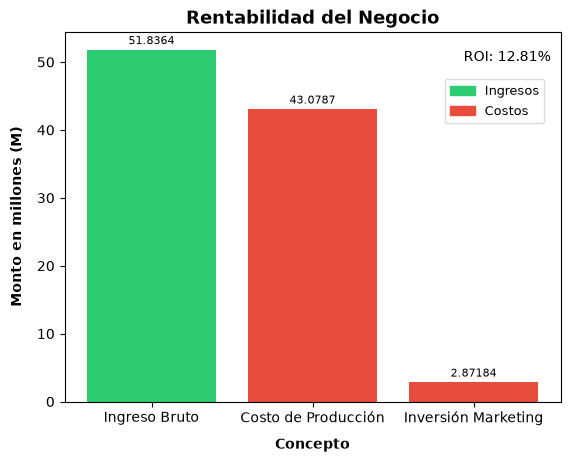

In [43]:
#Visualización
figRentabilidad= plt.figure() #Creamos figura
ax1=figRentabilidad.add_subplot() #Creamos container del plot
container=ax1.bar(xAxis,yMillionsAxis)
for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(
            f'{height:g}',
            (p.get_x() + p.get_width() / 2., p.get_y() + height),
            ha='center', va='bottom',
            xytext=(0, 2), textcoords='offset points',
            fontsize=8, fontweight='normal'
        )

categorias = xAxis
categoria_verde = "Ingreso Bruto"
for i, p in enumerate(ax1.patches):
    if i < len(categorias):
        cat_actual = str(categorias[i]).strip()

        if cat_actual in categoria_verde:
            p.set_facecolor('#2ecc71')  # Verde para positivos o ingresos
        else:
            p.set_facecolor('#e74c3c')  # Rojo para negativos o costos
ax1.text(
    0.98, 0.95,
    "ROI: "+str(ROI)+"%",
    transform=ax1.transAxes,
    ha='right', va='top',
    fontsize=10, fontweight='normal',
    color='black'
    )
leyenda_verde = mpatches.Patch(color='#2ecc71', label='Ingresos')
leyenda_roja = mpatches.Patch(color='#e74c3c', label='Costos')

# 3. Dibujar la leyenda (puedes ajustar 'loc' según tu gráfico)
ax1.legend(
    handles=[leyenda_verde, leyenda_roja],
    loc='upper right',
    bbox_to_anchor=(0.98, 0.89),
    frameon=True,
    facecolor='white',
    edgecolor='lightgray',
    fontsize=9
)
plt.title("Rentabilidad del Negocio",
         fontsize=13,
         fontweight='bold')
plt.ylabel("Monto en millones (M)",fontweight='bold',labelpad=9)
plt.xlabel("Concepto",fontweight='bold',labelpad=9)
plt.show()







In [44]:
#Parte 2: Comportamiento de ventas:
#Ticket promedio por orden:

AOV_total= np.round(orders_financial["ingreso_total"].mean(),2)
print(f'El tiquet promedio por orden es de: ${AOV_total}.')

#Variables y/o dataframes que usa el algoritmo de AOV acumulativo
AOV_mensual=np.round(orders_financial.groupby(by='mes_año').mean(numeric_only=True),2)['ingreso_total'] #El AOV por periodo, tipo dataframe.
nobs_mensual= np.round(orders_financial.groupby(by='mes_año').count(),2)['ingreso_total'] #número de obsevaciones por periodo, tipo dataframe.
periodos=["January-2025","February-2025","March-2025","April-2025","May-2025","June-2025"]


#Inicializamos el dataframe del AOV acumulativo.
AOV_mensual_acumulativo = pd.DataFrame(0, index=periodos,
                                       columns=['aov_mensual_acumulativo','nobs_acumulativo'],dtype="float64")

#El algoritmo del AOV acummulativo.

for i in range(len(periodos)):
    if i==0:
        AOV_mensual_acumulativo.loc[periodos[i],'aov_mensual_acumulativo']= np.round(AOV_mensual.loc[periodos[i]],2)
        AOV_mensual_acumulativo.loc[periodos[i],'nobs_acumulativo']= nobs_mensual.loc[periodos[i]]


    else:

        AOV_mensual_acumulativo.loc[periodos[i], 'aov_mensual_acumulativo'] = np.round(
    (
        (AOV_mensual_acumulativo.loc[periodos[i - 1], 'aov_mensual_acumulativo'] *
         AOV_mensual_acumulativo.loc[periodos[i - 1], 'nobs_acumulativo'] +
         AOV_mensual.loc[periodos[i]] * nobs_mensual.loc[periodos[i]]) /
        (nobs_mensual.loc[periodos[i]] +
         AOV_mensual_acumulativo.loc[periodos[i - 1], 'nobs_acumulativo'])
    ),
    2)
        AOV_mensual_acumulativo.loc[periodos[i],'nobs_acumulativo']= (nobs_mensual.loc[periodos[i]]+
                                                                            AOV_mensual_acumulativo.loc[periodos[i-1],'nobs_acumulativo'])




#Cantidad promedio por orden
cantidad_promedio= np.round(orders_financial["cantidad"].mean(),0).astype(int)
print (f"La cantidad promedio por orden es de: {cantidad_promedio} unidades.")
cantidad_mediana=np.round(orders_financial["cantidad"].median(),0).astype(int)

#Producto más vendido
cantidades_totales_producto=orders_financial.groupby(["nombre_producto"])["cantidad"].sum()
producto_top=cantidades_totales_producto.idxmax()
cantidad_top= int(cantidades_totales_producto.max())
print(f"El producto mas vendido es {producto_top} con {cantidad_top} unidades.")


#Gasto en marketing por canal
gasto_marketing_canal = (
    marketing
    .groupby('canal', as_index=False)
    .agg(gasto=('gasto', 'sum'))
)





El tiquet promedio por orden es de: $2107.17.
La cantidad promedio por orden es de: 7 unidades.
El producto mas vendido es Laptop-Gaming-16GB con 144160 unidades.


El algoritmo de AOV acumulado que implemente se basa en la siguiente ecuación matemática:
$$\text{AOV}_{\text{acumulado}, i} = \frac{\text{AOV}_{\text{acumulado}, i-1} \cdot n_{\text{acumulado}, i-1} + \text{AOV}_{\text{puntual}, i} \cdot n_{\text{puntual}, i}}{n_{\text{acumulado}, i-1} + n_{\text{puntual}, i}}$$

De tal manera que:
- $i$: es el índice del periodo actual ($i = 0,1, 2, \dots, N$).
- $n_{\text{puntual}, i}$: es el número de observaciones (ingresos) en el periodo $i$.
- $\text{AOV}_{\text{puntual}, i}$: es el ticket promedio calculado de manera aislada para el periodo $i$.
- $n_{\text{acumulado}, i-1}$: es la suma total de observaciones desde el periodo $1$ hasta el periodo previo $i-1$.
- $\text{AOV}_{\text{acumulado}, i-1}$: es el ticket promedio acumulado histórico hasta el periodo previo $i-1$.
- $\text{AOV}_{\text{acumulado}, i}$: es el nuevo ticket promedio acumulado actualizado al incluir el $\text{AOV}_{\text{puntual}}$  del periodo $i$.
- Cuando $i=0$ entonces  $\text{AOV}_{\text{acumulado}, 0}=\text{AOV}_{\text{puntual}, 0}$

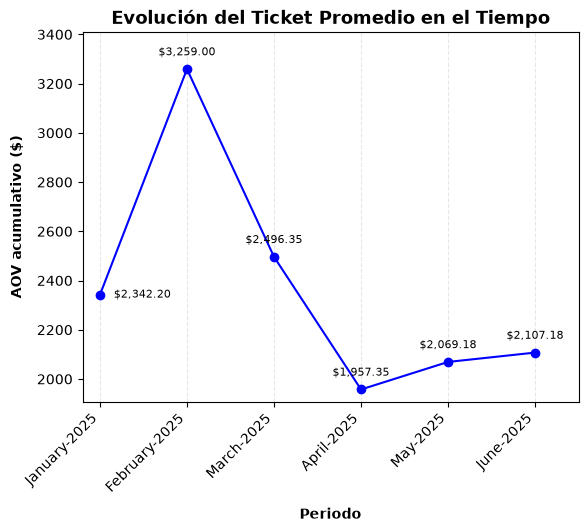

In [45]:
#Visualización 1
figaov= plt.figure() #Creamos figura
ax2 = figaov.add_subplot()  # Creamos container del plot
x = periodos
y = AOV_mensual_acumulativo['aov_mensual_acumulativo']

ax2.plot(x, y, 'bo', linestyle='-')
plt.xticks(rotation=45, ha='right')

for i in range(len(y)):
    val_y = y.iloc[i] if hasattr(y, 'iloc') else y[i]
    val_x = x.iloc[i] if hasattr(x, 'iloc') else x[i]

    if i == 0:
        offset = (10, 0)
        ha_align, va_align = 'left', 'center'
    else:
        offset = (0, 8)
        ha_align, va_align = 'center', 'bottom'

    ax2.annotate(
        f"${val_y:,.2f}",  
        xy=(val_x, val_y),
        xytext=offset,
        textcoords='offset points',
        ha=ha_align,
        va=va_align,
        fontsize=8,
        fontweight='normal'
    )

ax2.set_xlim(-0.2, len(x) - 0.5)
ax2.set_ylim(y.min() - 50, y.max() + 150)
ax2.set_ylabel(
    'AOV acumulativo ($)',
    fontsize=10,
    fontweight='bold',
    color='black',
    labelpad=9,
    rotation=90
)
ax2.set_xlabel(
    'Periodo',
    fontsize=10,
    fontweight='bold',
    color='black',
    labelpad=9,
)
ax2.grid(axis='x', linestyle='--', alpha=0.3)
plt.title("Evolución del Ticket Promedio en el Tiempo",
          fontsize=13,
          fontweight="bold")

plt.show()



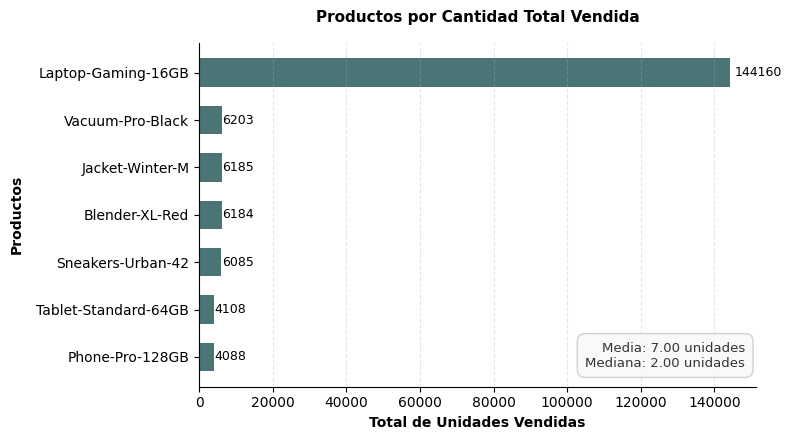

In [ ]:
#Visualización 2

cantidad_productos = (
    orders_financial.groupby('nombre_producto')['cantidad']
    .sum()
    .sort_values(ascending=False)
)


fig, ax3 = plt.subplots(figsize=(8, 4.5))
bars = ax3.barh(
    cantidad_productos.index,
    cantidad_productos.values,
    color='#2b5c5f',
    alpha=0.85,
    height=0.6
)


for bar in bars:
    width = bar.get_width()
    ax3.text(
        width + (width * 0.01),
        bar.get_y() + bar.get_height() / 2,
        int(width),
        va='center',
        ha='left',
        fontsize=9,
        fontweight='normal'
    )

ax3.set_title('Productos por Cantidad Total Vendida', fontsize=11, fontweight='bold', pad=15)
ax3.set_xlabel('Total de Unidades Vendidas', fontsize=10,fontweight='bold')
ax3.set_ylabel(
    'Productos',
    fontsize=10,
    fontweight='bold',
    color='black',
    labelpad=9,
    rotation=90
)
ax3.invert_yaxis()
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.grid(axis='x', linestyle='--', alpha=0.3)

texto_kpi = f'Media: {cantidad_promedio:.2f} unidades\nMediana: {cantidad_mediana:.2f} unidades'

ax3.text(
    0.98, 0.05,
    texto_kpi,
    transform=ax3.transAxes,
    ha='right', va='bottom',
    fontsize=9.5,
    fontweight='medium',
    color='#333333',
    bbox=dict(
        boxstyle='round,pad=0.6',
        facecolor='#f8f9fa',
        edgecolor='#cccccc',
        alpha=0.9
    )
)

plt.tight_layout()
plt.show()

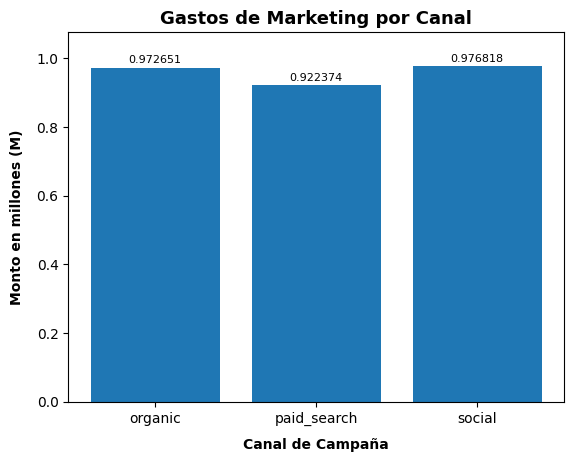

In [ ]:
#Visualización 3
y=np.array(gasto_marketing_canal['gasto'])/1_000_000
figMarketing= plt.figure() #Creamos figura
ax4=figMarketing.add_subplot() #Creamos container del plot
ax4.bar(gasto_marketing_canal['canal'],y) #Adjust to scale in Millions
for p in ax4.patches:
    height = p.get_height()
    if height > 0:
        ax4.annotate(
            f'{height:g}',
            (p.get_x() + p.get_width() / 2., p.get_y() + height),
            ha='center', va='bottom',
            xytext=(0, 2), textcoords='offset points',
            fontsize=8, fontweight='normal'
        )
ax4.set_ylim(0 , max(y)+0.1 )
plt.title("Gastos de Marketing por Canal",
          fontsize=13,
          fontweight='bold')

plt.ylabel("Monto en millones (M)",labelpad=9,fontweight='bold')
plt.xlabel("Canal de Campaña",labelpad=9, fontweight='bold')
plt.show()

## 🔹 Paso 3: Análisis de pérdida de usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.



**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  



**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?


In [ ]:
#Este paquete no viene preinstalado en colab cada sesion en cada VM requiere volverlo a instalar
#Sin este paquete no va a funcionar create_engine
!pip install "psycopg"

In [ ]:
import pandas as pd
from sqlalchemy import create_engine
user=userdata.get("USER")
password=userdata.get("PWD")
host=userdata.get("HOST")
port=userdata.get("PORT")
db=userdata.get("DB")

db_config = {
    'user': user,
    'pwd': password,
    'host': host,
    'port': port,
    'db': db
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [ ]:
# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [ ]:
#Etapas del funnel
#El orden de eventos según el flujo de usuarios
#1- first_visit
#2-select_item
#3-add_to_cart
#4-begin_checkout
#5-add_payment_info
#6-purchase
events['nombre_evento'].unique()

array(['first_visit', 'add_to_cart', 'add_payment_info', 'purchase',
       'begin_checkout', 'select_item'], dtype=object)

In [ ]:
# PARTE 1: Totales de usuarios por etapa del funnel
# ======================

query_totals = '''
SELECT nombre_evento , COUNT(DISTINCT id_usuario) AS numero_usuarios FROM events  --Comment: conteo de usuarios únicos
GROUP BY nombre_evento
ORDER BY  -- Comment: Orden segun flujo de usuarios
    CASE nombre_evento
        WHEN 'first_visit' THEN 1
        WHEN  'select_item' THEN 2
        WHEN 'add_to_cart' THEN 3
        WHEN 'begin_checkout' THEN 4
        WHEN 'add_payment_info' THEN 5
        ELSE 7
        END ASC
'''

totals = pd.read_sql(query_totals, con=engine)
totals

,nombre_evento,numero_usuarios
0,first_visit,7796
1,select_item,7582
2,add_to_cart,7634
3,begin_checkout,7208
4,add_payment_info,6250
5,purchase,6240


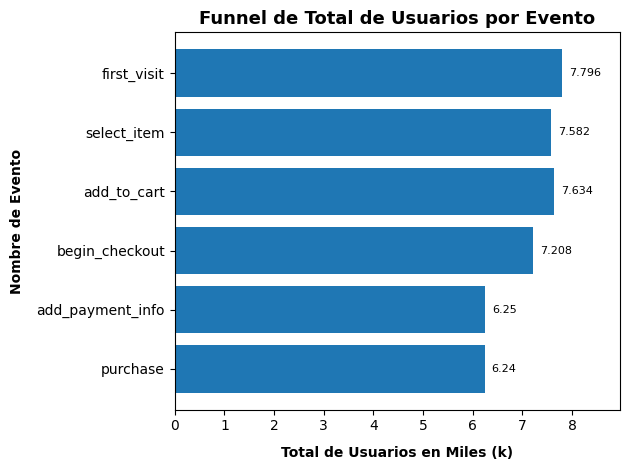

In [ ]:
#Visualización
y = np.array(totals['numero_usuarios']) / 1_000
x_labels = totals['nombre_evento']

figUsuarios = plt.figure()
ax5 = figUsuarios.add_subplot()


ax5.barh(x_labels, y)


ax5.invert_yaxis()

for p in ax5.patches:
    width = p.get_width()
    if width > 0:
        ax5.annotate(
            f'{width:g}',
            (p.get_x() + width, p.get_y() + p.get_height() / 2.),
            ha='left', va='center',
            xytext=(5, 0), textcoords='offset points',
            fontsize=8, fontweight='normal'
        )


ax5.set_xlim(0, max(y) * 1.15)

plt.title("Funnel de Total de Usuarios por Evento", fontsize=13, fontweight='bold')
plt.ylabel("Nombre de Evento", labelpad=9, fontweight='bold')
plt.xlabel("Total de Usuarios en Miles (k)", labelpad=9, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# PARTE 2: Conversiones
# ======================

query_conversion = '''
WITH conteos_funnel AS (
    SELECT nombre_evento , COUNT(DISTINCT id_usuario) AS numero_usuarios FROM events
    GROUP BY nombre_evento
    ORDER BY
        CASE nombre_evento
            WHEN 'first_visit' THEN 1
            WHEN  'select_item' THEN 2
            WHEN 'add_to_cart' THEN 3
            WHEN 'begin_checkout' THEN 4
            WHEN 'add_payment_info' THEN 5
            ELSE 7
            END ASC
    ),
conteo_first_visit AS (SELECT nombre_evento, numero_usuarios
    FROM conteos_funnel WHERE nombre_evento ='first_visit'),

conteo_select_item AS (SELECT nombre_evento, numero_usuarios
    FROM conteos_funnel WHERE nombre_evento ='select_item'),

conteo_add_to_cart AS (SELECT nombre_evento, numero_usuarios
    FROM conteos_funnel WHERE nombre_evento ='add_to_cart'),

conteo_begin_checkout AS (SELECT nombre_evento, numero_usuarios
    FROM conteos_funnel WHERE nombre_evento ='begin_checkout'),

conteo_add_payment_info AS (SELECT nombre_evento, numero_usuarios
    FROM conteos_funnel WHERE nombre_evento ='add_payment_info'),

conteo_purchase AS (SELECT nombre_evento, numero_usuarios
    FROM conteos_funnel WHERE nombre_evento ='purchase'),

conversion_first_visit_to_select_item AS (SELECT CONCAT('conv','_',fv.nombre_evento,'_','to','_',si.nombre_evento) AS nombre_conversion,
                                                            ROUND((si.numero_usuarios*100.0)/NULLIF(fv.numero_usuarios,0),2) AS tasa_conversion
    FROM conteo_first_visit AS fv, conteo_select_item AS si),

conversion_first_visit_to_add_to_cart AS (SELECT CONCAT('conv','_',fv.nombre_evento,'_','to','_',ac.nombre_evento) AS nombre_conversion,
                                                            ROUND((ac.numero_usuarios*100.0)/NULLIF(fv.numero_usuarios,0),2) AS tasa_conversion
    FROM conteo_first_visit AS fv, conteo_add_to_cart AS ac),

conversion_first_visit_to_begin_checkout AS (SELECT CONCAT('conv','_',fv.nombre_evento,'_','to','_',bc.nombre_evento) AS nombre_conversion,
                                                            ROUND((bc.numero_usuarios*100.0)/NULLIF(fv.numero_usuarios,0),2) AS tasa_conversion
    FROM conteo_begin_checkout AS bc, conteo_first_visit AS fv),

conversion_first_visit_to_add_payment_info AS (SELECT CONCAT('conv','_',fv.nombre_evento,'_','to','_',ap.nombre_evento) AS nombre_conversion,
                                                            ROUND((ap.numero_usuarios*100.0)/NULLIF(fv.numero_usuarios,0),2) AS tasa_conversion
    FROM conteo_first_visit AS fv, conteo_add_payment_info AS ap),

conversion_first_visit_to_purchase AS (SELECT CONCAT('conv','_',fv.nombre_evento,'_','to','_',p.nombre_evento) AS nombre_conversion,
                                                            ROUND((p.numero_usuarios*100.0)/NULLIF(fv.numero_usuarios,0),2) AS tasa_conversion
    FROM conteo_purchase AS p, conteo_first_visit AS fv)

SELECT *
FROM conversion_first_visit_to_select_item
UNION ALL
SELECT *
FROM conversion_first_visit_to_add_to_cart
UNION ALL
SELECT *
FROM conversion_first_visit_to_begin_checkout
UNION ALL
SELECT *
FROM conversion_first_visit_to_add_payment_info
UNION ALL
SELECT *
FROM conversion_first_visit_to_purchase



'''

conversion = pd.read_sql(query_conversion, con=engine)
conversion


,nombre_conversion,tasa_conversion
0,conv_first_visit_to_select_item,97.26
1,conv_first_visit_to_add_to_cart,97.92
2,conv_first_visit_to_begin_checkout,92.46
3,conv_first_visit_to_add_payment_info,80.17
4,conv_first_visit_to_purchase,80.04


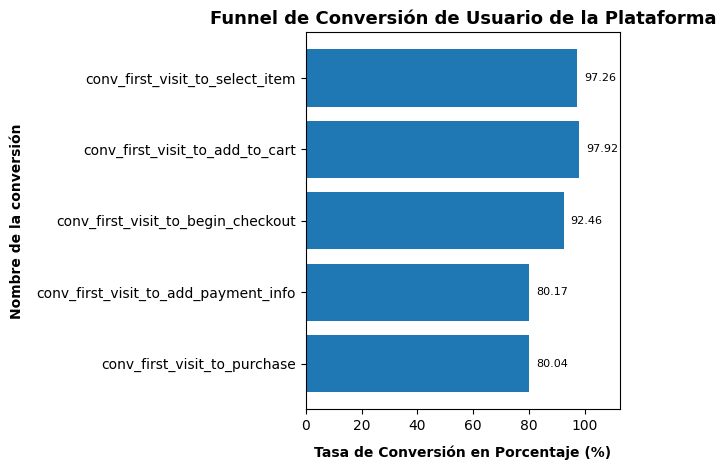

In [ ]:
#Visualización
y = np.array(conversion['tasa_conversion'])
x_labels = conversion['nombre_conversion']

figConversion = plt.figure()
ax6 = figConversion.add_subplot()


ax6.barh(x_labels, y)


ax6.invert_yaxis()

for p in ax6.patches:
    width = p.get_width()
    if width > 0:
        ax6.annotate(
            f'{width:g}',
            (p.get_x() + width, p.get_y() + p.get_height() / 2.),
            ha='left', va='center',
            xytext=(5, 0), textcoords='offset points',
            fontsize=8, fontweight='normal'
        )


ax6.set_xlim(0, max(y) * 1.15)

plt.title("Funnel de Conversión de Usuario de la Plataforma", fontsize=13, fontweight='bold')
plt.ylabel("Nombre de la conversión", labelpad=9, fontweight='bold')
plt.xlabel("Tasa de Conversión en Porcentaje (%)", labelpad=9, fontweight='bold')

plt.tight_layout()
plt.show()


### Comentario del Analista
**Punto crítico:** La mayor pérdida (drop-off) de usuarios ocurre en el paso de `add_payment_info`.

**Anomalía en el embudo:** Se observa una tasa de conversión superior en `conv_first_visit_to_add_to_cart` frente a `conv_first_visit_to_select_item` así como en el número total de usuarios entre `select_item` y `add_to_cart`. Esta dinámica responde al diseño de interacción (UX) del sitio: aunque `first_visit` es la entrada universal, `select_item` no es un requisito obligatorio para avanzar. Los botones de compra directa en la plataforma permiten a los usuarios agregar productos al carrito sin acceder previamente a la vista detallada del producto.

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users`
- `user_activity`

1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  



In [ ]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free


In [ ]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT *
FROM user_activity;
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1


In [ ]:
#El número de meses únicos para la cohortes
numero_meses_cohorte=pd.to_datetime(users['fecha_registro'],errors='coerce').dt.month.nunique()
#El número de años unicos para las cohortes
numero_años_cohorte= pd.to_datetime(users['fecha_registro'],errors='coerce').dt.year.nunique()
print(f'número de meses en el análisis de cohortes: {numero_meses_cohorte}')
print(f'número de años en el análisis de cohortes: {numero_años_cohorte}')
#Por ende tendremos 5 cohortes en el año 2025

número de meses en el análisis de cohortes: 5
número de años en el análisis de cohortes: 1


In [ ]:
# Retención por cohortes
# ======================
query_cohort_retention_final = '''
WITH cohorte_mensuales AS (SELECT id_usuario,
DATE_TRUNC('month',MIN(fecha_registro::TIMESTAMP)) as cohort_mensual
FROM users
GROUP BY id_usuario),

actividad_usuario_con_cohorte AS (SELECT ua.id_usuario, ua.fecha_actividad,ua.activo,cm.cohort_mensual
FROM user_activity AS ua
LEFT JOIN cohorte_mensuales AS cm
ON ua.id_usuario= cm.id_usuario)

SELECT cohort_mensual,COUNT(DISTINCT CASE
            WHEN ((CAST(fecha_actividad AS DATE)-CAST(cohort_mensual AS DATE)))>=7 AND activo=1 THEN id_usuario
            END) AS number_users_w1, COUNT(DISTINCT CASE
            WHEN ((CAST(fecha_actividad AS DATE)-CAST(cohort_mensual AS DATE)))>=14 AND activo=1 THEN id_usuario
            END) AS number_users_w2,COUNT(DISTINCT CASE
            WHEN ((CAST(fecha_actividad AS DATE)-CAST(cohort_mensual AS DATE)))>=21 AND activo=1 THEN id_usuario
            END) AS number_users_w3
FROM actividad_usuario_con_cohorte
GROUP BY cohort_mensual


'''

# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final['cohort_mensual']=cohorte_final['cohort_mensual'].astype(str)
cohorte_final= cohorte_final.set_index('cohort_mensual')
cohorte_final



,number_users_w1,number_users_w2,number_users_w3
cohort_mensual,,,
2025-01-01,1381,1355,1288
2025-02-01,1255,1237,1167
2025-03-01,1428,1396,1319
2025-04-01,1394,1362,1279
2025-05-01,1446,1409,1332


In [ ]:
#Promedios de oscilación
cohorte_final.mean()

,0
number_users_w1,1380.8
number_users_w2,1351.8
number_users_w3,1277.0


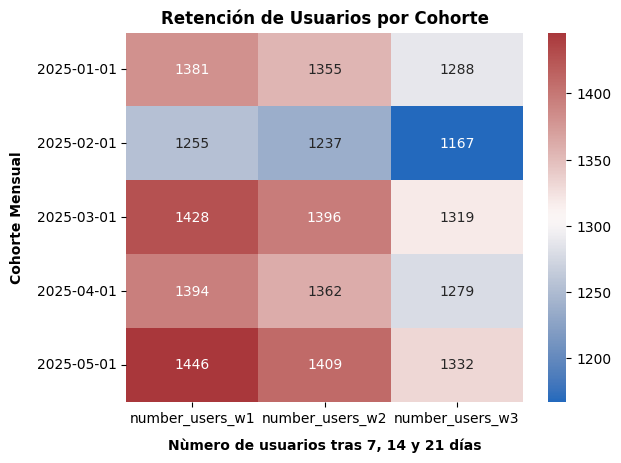

In [ ]:
#Visualizacion
sns.heatmap(cohorte_final,cmap='vlag',annot=True,fmt='d',annot_kws={'size': 10})
plt.xlabel("Nùmero de usuarios tras 7, 14 y 21 días",labelpad=9,fontweight='bold',fontsize=10)
plt.ylabel("Cohorte Mensual",labelpad=9,fontweight='bold',fontsize=10)
plt.title("Retención de Usuarios por Cohorte",fontweight='bold')
plt.show()

In [ ]:
#Porcentaje de retención
query_cohort_retention_final = """
WITH cohorte_mensuales AS (SELECT id_usuario,
DATE_TRUNC('month',MIN(fecha_registro::TIMESTAMP)) as cohort_mensual
FROM users
GROUP BY id_usuario),

actividad_usuario_con_cohorte AS (SELECT ua.id_usuario, ua.fecha_actividad,ua.activo,cm.cohort_mensual
FROM user_activity AS ua
LEFT JOIN cohorte_mensuales AS cm
ON ua.id_usuario= cm.id_usuario)

SELECT cohort_mensual,(COUNT(DISTINCT CASE
            WHEN (CAST(fecha_actividad AS DATE)-CAST(cohort_mensual AS DATE))>=7 AND activo=1 THEN id_usuario
            END)*100.0/NULLIF(COUNT(id_usuario),0)) AS pct_retencion_usuarios_w1,

            (COUNT(DISTINCT CASE
            WHEN (CAST(fecha_actividad AS DATE)-CAST(cohort_mensual AS DATE))>=14 AND activo=1 THEN id_usuario
            END)*100.0/NULLIF(COUNT(id_usuario),0)) AS pct_retencion_usuarios_w2,

            (COUNT(DISTINCT CASE
            WHEN (CAST(fecha_actividad AS DATE)-CAST(cohort_mensual AS DATE))>=21 AND activo=1 THEN id_usuario
            END)*100.0/NULLIF(COUNT(id_usuario),0)) AS pct_retencion_usuarios_w3
FROM actividad_usuario_con_cohorte
GROUP BY cohort_mensual

"""
# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final['cohort_mensual']=cohorte_final['cohort_mensual'].astype(str)
cohorte_final= cohorte_final.set_index('cohort_mensual')
cohorte_final

,pct_retencion_usuarios_w1,pct_retencion_usuarios_w2,pct_retencion_usuarios_w3
cohort_mensual,,,
2025-01-01,21.220037,20.820529,19.791026
2025-02-01,21.727839,21.416205,20.204294
2025-03-01,21.821516,21.332518,20.155868
2025-04-01,21.699875,21.201743,19.909714
2025-05-01,21.428571,20.880261,19.739182


In [ ]:
#promedio de retención
cohorte_final.mean()

,0
pct_retencion_usuarios_w1,21.579568
pct_retencion_usuarios_w2,21.130251
pct_retencion_usuarios_w3,19.960017


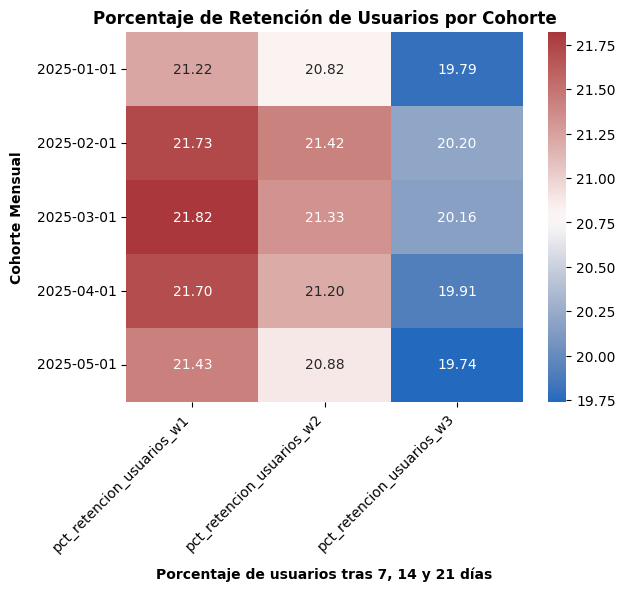

In [ ]:
#Visualizacion
sns.heatmap(cohorte_final,cmap='vlag',annot=True,fmt='.2f',annot_kws={'size': 10})
plt.xlabel("Porcentaje de usuarios tras 7, 14 y 21 días",labelpad=9,fontweight='bold',fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.ylabel("Cohorte Mensual",labelpad=9,fontweight='bold',fontsize=10)
plt.title("Porcentaje de Retención de Usuarios por Cohorte",fontweight='bold')
plt.show()

## 🔹 Paso 5: Validar si los cambios generan impacto (A/B testing)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.



Hipótesis estadística
   - **H₀ (Hipótesis nula):**  No hay evidencia estadística suficiente para afirmar que la versión con tratamiento (cambios implementados en la UI del checkout ) modifique la *tasa de conversión* respecto a la versión de control (el status quo o página a priori). $$p_{treatment}=p_{control}$$
   - **H₁ (Hipótesis alternativa):** Hay evidencia estadística suficiente para afirmar que la versión con tratamiento (cambios implementados en la UI del checkout) modifica de forma significativa la *tasa de conversión* respecto a la versión de control (el status quo o página a priori).$$p_{treatment} \neq p_{control}$$
   
**Test estadístico:** Dos proporciones z-test  
**Nivel de significancia alpha:** 5%

In [46]:
#Se importan los valores de las rutas.
experiment=os.getenv("EXPERIMENT")

In [47]:

experiment_checkout_ui = pd.read_csv(experiment)
experiment_checkout_ui.head()


,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18
3,exp_user_3,tratamiento,0,mobile,Colombia,151.45,2025-06-03
4,exp_user_4,tratamiento,0,desktop,Mexico,299.96,2025-01-12


In [48]:
#Divividmos muestra A-control con conversion
n_converted_control=experiment_checkout_ui[(experiment_checkout_ui['variante']=='control') & (experiment_checkout_ui['convirtio']==1)].shape[0]
n_converted_control

779

In [49]:
#Divividmos muestra A-control total
n_control=experiment_checkout_ui[experiment_checkout_ui['variante']=='control'].shape[0]
n_control

4965

In [50]:
#Divividmos muestra B-control con conversion
n_converted_treatment=experiment_checkout_ui[(experiment_checkout_ui['variante']=='tratamiento') & (experiment_checkout_ui['convirtio']==1)].shape[0]
n_converted_treatment

820

In [51]:
#Divividmos muestra B-control total
n_treatment=experiment_checkout_ui[experiment_checkout_ui['variante']=='tratamiento'].shape[0]
n_treatment

5035

In [52]:
n_converted=np.array([n_converted_treatment, n_converted_control])
n_total=np.array([n_treatment,n_control])
print ("n_converted (treatment, control): ",n_converted)
print ("n_total (treatment, control): ", n_total)

n_converted (treatment, control):  [820 779]
n_total (treatment, control):  [5035 4965]


In [53]:
# Dos proporciones z-test
#probamos se cumplan aseveraciones para cumplir con CLT (Teorema limite central)
#n*(p)>=10 y n(1-p)>=10
# alpha=0.05

if (n_control*n_converted_control/n_control>=10 and n_treatment*n_converted_treatment/n_treatment>=10 and
    n_control*(1-n_converted_control/n_control)>=10 and n_treatment*(1-n_converted_treatment/n_treatment)>=10):
    stat, pval = proportions_ztest(n_converted, n_total)
    print (f'z-Value es de :{stat}, p-value es de {pval} ' )




z-Value es de :0.8132782986429474, p-value es de 0.41605851639119995 


#### Interpretación del analista:
La comparación de proporciones mediante la prueba $Z$ entre el grupo de control y la muestra con tratamiento no resultó estadísticamente significativa ($p = 0.42 \ge \alpha$). Al no rechazar la hipótesis nula, se concluye que los datos recopilados no muestran evidencia suficiente de un cambio en la tasa de conversión atribuible al tratamiento.

## 🔹 Paso 6: Comunicar los resultados (Dashboard en BI)

🎯 **Objetivo**:  
Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión.



Dashboard 1: Overview Ejecutivo
**KPIs principales a mostrar:**
- Revenue total
- Profit total
- Gasto total en marketing
- Ticket promedio
- Cantidad promedio de productos por orden


Dashboard 2: Detalle / Drill-through  
**Objetivo:** Permitir explorar los datos desde el KPI general hasta cada orden o producto.

Para Visualizar el archivo Power BI o el notebook pueden revisar mi repositorio en Github. El notebook de Collab tiene adaptaciones a la infraestructura interna mientras que el de Github es el notebook cuando se ejecuta en un entorno local.

[Mi Github repo: RappiPlus Analysis](https://github.com/Pablro/RappiPlus_analysis)


### Hallazgos y Sugerencias del Negocio

#### 1. Análisis de Limpieza de Datos
- **Contexto:**
  - Se realizó una limpieza de datos con datos ausentes de tipo MNAR y duplicados.
  - Se auditó la consistencia financiera del dataset mediante la reconciliación entre el volumen de ventas, precios unitarios, descuentos aplicados y el ingreso total registrado.
- **Hallazgo:**
  - Se registró una pérdida de información del $2\%$ (por debajo del umbral de tolerancia del 5%), con un impacto marginal del $-0.36\%$ en los ingresos facturados.
  - El $72\%$ de las transacciones muestra coincidencia exacta entre el monto facturado y el monto esperado según reglas de negocio.
- **Recomendación de Acción:**
  - Se sugiere revisar los procesos de captura en el origen para reducir patrones de datos faltantes recurrentes, registros duplicados e inconsistencias. Dado su bajo impacto actual en el análisis global, esta acción no bloquea las operaciones actuales, pero fortalecerá la calidad de la información a futuro.
  - Auditar de manera prioritaria el $28\%$ de las transacciones con inconsistencias entre la facturación real y la teórica, con el fin de mitigar riesgos de cartera vencida, cobros erróneos y afectaciones en la experiencia del cliente.

#### 2. Análisis de Rentabilidad
- **Contexto:**
      - Si bien los ingresos brutos proyectan un margen positivo inicial, la alta concentración en costos de producción (alrededor de un 85% de los ingresos brutos) en comparación con marketing (5%) deja un margen de maniobra estrecho. Bajo un análisis financiero integral, esta relación resulta vulnerable al incorporar los gastos de administración u otras cargas financieras que diluirían sensiblemente la utilidad neta.
      - Respecto al ticket promedio o AOV (Average Order Value), se registra un valor total de \$ 2107.18 durante el periodo de enero a junio de 2025.
      - Respecto al producto más vendido encontramos a Laptop Gaming 16GB con 144,160 unidades.
      - Los gastos asociados a los canales de campañas de marketing muestran un comportamiento estable, manteniéndose en un rango de 900,000 a 1000,000,000.
- **Hallazgo:**
  - Desde una perspectiva estrictamente comercial, el ROI del 12% presenta un indicador positivo a primera vista. Sin embargo, este resultado es incompleto: su suficiencia real permanece condicionada a si cumple con la tasa de retorno esperada y los criterios de margen del área financiera.
  - Febrero registra el ticket promedio (AOV) acumulado más alto del periodo analizado, situándose en alrededor de \$3259. Sin embargo, este valor representa un comportamiento atípico dentro del patrón general de evolución de la métrica.
  - El producto de Laptop Gaming 16GB tiene una cantidad de unidades vendidas de 23 veces o mas que cualquier otro producto, sesgando dramáticamente la distribución de unidades vendidas. Cabe preguntarse que relación con el patrón atípico del AOV visto en Febrero y su misma relación a los ingresos brutos y costos operativos de la empresa.
  - En términos de estructura financiera, esta inversión representa un peso controlado al no superar el 5% de los ingresos brutos de la compañía.  
- **Recomendación de Acción:**
  - Para blindar la rentabilidad, la acción preventiva prioritaria es optimizar la estructura de costos de producción. De no existir margen de maniobra en los costos, la estrategia deberá enfocarse en incrementar el precio unitario o el valor promedio por venta, maximizando así la brecha entre el ingreso bruto y el costo operativo.
  - Se recomienda utilizar el valor de enero (\$2342) como línea base (baseline) para la planeación estratégica del ticket promedio. Esto se debe a que la anomalía puntual de febrero distorsiona al alza el indicador acumulado de marzo, mientras que el resto de los meses muestra un comportamiento estable por debajo de este umbral.
  -Es necesario realizar una revisión exhaustiva sobre las ventas de Laptops Gaming 16GB, dado que muestran una desviación atípica con un peso significativo en los ingresos. Su naturaleza como producto de alta gama (high-ticket) contrasta con la dinámica de compra recurrente de la plataforma, por lo que aislar o validar esta cifra es crítico para no afectar a los intereses del negocio.
- Dada la consistencia en la estructura de gastos, se recomienda auditar la rentabilidad individual de cada canal de campaña. El objetivo es corroborar si su costo operativo queda plenamente absorbido por su contribución a los ingresos o si requiere una reoptimización.

#### 3. Análisis de Funnel de Conversión
- **Contexto:**
  - La mayor caída de usuarios en la plataforma se identicó ser en la etapa `add_payment_info` con una retención de usuarios desde `first_visit` del 80% y reflejando una caída de usuarios  llendo de 7,796 a 6,250 usuarios.
  - En la estructura estándar de un embudo de conversión, las tasas de retención disminuyen de forma progresiva a medida que se avanza en las etapas del flujo (`first_visit` $\rightarrow$ `select_item` $\rightarrow$ `add_to_cart`). No obstante, los datos muestran un comportamiento anómalo: la tasa de conversión de `first_visit` a `add_to_cart` (97.92%) supera a la de `first_visit` a `select_item` (97.26%).
- **Hallazgo:**
  - La transición entre `first_visit` y `add_payment_info` constituye el principal cuello de botella del embudo, registrando la mayor fuga de usuarios con una caída de aproximadamente el 17% en la conversión.
  - Se detectó una inversión anómala en las tasas de conversión del embudo. La conversión hacia `add_to_cart` (97.92%) es superior a la etapa previa de `select_item` (97.26%). Este comportamiento confirma cuantitativamente la existencia de flujos de compra no lineales, donde un porcentaje significativo de usuarios añade productos al carrito directamente (por ejemplo, desde tarjetas de catálogo o recomendaciones) sin pasar por la vista detallada del artículo (`select_item`).
- **Recomendación de Acción:**
  - Se recomienda auditar los flujos de conversión no lineales mediante analítica de interacción (clickstream) y mitigar las caídas detectadas en etapas críticas, como `add_payment_info`. La estrategia de UX debe priorizar la optimización de los accesos directos de compra y la resolución de estos puntos de fricción para acelerar el proceso de pago, maximizar la tasa de conversión y sostener el crecimiento de los ingresos.

#### 4. Análisis de Retención de Cohortes
- **Contexto:** Evaluación de la retención de usuarios a 7, 14 y 21 días mediante dos métricas distintas: el volumen absoluto de usuarios retenidos (donde destaca la cohorte 2025-05-01) y el porcentaje de retención sobre el total (donde destaca la cohorte 2025-02-01).
- **Hallazgo:**
  - Contraste de  Volumen vs. Eficiencia: La cohorte de mayo (2025-05-01) domina en escala al mantener la mayor masa de usuarios activos (1,446 a los 7 días), pero se diluye rápidamente. En contraste, febrero (2025-02-01) lidera en eficiencia, logrando la mejor conversión de retención en todo el ciclo (21.73% a los 7 días y 20.20% a los 21 días).

   - Calidad Integral de Cohorte: Febrero destaca como la cohorte más sólida del periodo: no solo maximiza la eficiencia final al día 21 (20.20%), sino que protege mejor la base al registrar la menor fuga interperiodo (-1.53 pp vs. -1.69 pp en mayo). Sin embargo, bajo una métrica pura de volumen total de retención, mayo continúa siendo la cohorte líder.

   - La media de usuarios mantiene una masa crítica y una tasa estables hasta la segunda semana, pasando de 1,381 a 1,352 usuarios promedio (21.57% a 21.13%). Sin embargo, el quiebre principal ocurre en la tercera semana, donde la retención cae al 19.96%, registrando una fuga acelerada que reduce la masa retenida a 1,277 usuarios promedio (una pérdida neta de ~104 usuarios frente al día 7).
- **Recomendación de Acción:**


 - Elevación del baseline temprano (Día 7): Implementar estrategias comerciales y de activación inmediata para elevar la tasa media general. Iniciar el periodo con solo un ~20%, retención al día 7 (21.57%), evidencia una pérdida acelerada en los primeros días, por lo que existe un alto margen de optimización previo a la primera semana.

 - Estrategia por masa (Cohorte Mayo): Si la prioridad del negocio es capturar mayor volumen de usuarios, replicar la estrategia de captación de la cohorte de mayo. Dada su menor eficiencia de permanencia temporal, se deben enfocar los rendimientos comerciales y de consumo en el corto plazo (primeros 14 días).

 - Estrategia por eficiencia (Cohorte Febrero): Si la prioridad comercial se fundamenta en la eficiencia de retención, tomar como modelo la cohorte de febrero para estructurar iniciativas orientadas a la lealtad y retención del cliente a largo plazo.


#### 5. Análisis de Prueba A/B
- **Contexto:**
  - Este experimento evalúa si un rediseño de UI en el checkout incrementa la tasa de conversión, aplicando una prueba de hipótesis de de 2 proporciones (Z-test). Aunque la captura de datos incluye métricas contextuales (dispositivo, país, duración de sesión y timestamp), el análisis estadístico se centra exclusivamente en evaluar la diferencia entre la variante asignada (control vs. tratamiento) y el resultado de conversión para cada identificador de usuario.
- **Hallazgo:**
  - La prueba de proporciones Z-test entre el grupo de control y el de tratamiento no mostró diferencias estadísticamente significativas ($p = n \ge \alpha$). Al no rechazar la hipótesis nula, se concluye que los datos no aportan suficiente evidencia de generar un impacto medible en la tasa de conversión tras el rediseño de UI en el checkout, en comparación con la versión previa (status quo)
- **Recomendación de Acción:**
 - Mitigación del sesgo organizacional (Ante discrepancia con otras métricas): En caso de escepticismo sobre los resultados debido a evidencias históricas o métricas internas previas, iterar mediante un nuevo diseño experimental aleatorizado. Se debe optimizar la potencia estadística ($1-\beta$) incrementando el tamaño muestral o ajustando la varianza para detectar efectos de menor magnitud sin incurrir en falsos negativos.
 - Rediseño iterativo (Ante alineación con sospechas previas): Si la falta de significancia estadística confirma hipótesis o deficiencias identificadas en otros canales, replantear la propuesta de valor en la UI del checkout. Posterior al rediseño, estructurar una nueva batería de experimentos para medir el impacto real sobre la conversión previo al despliegue definitivo.

#### 6. Análisis con Power BI
- **Contexto:**

  - Los datos depurados se importaron a Power BI para el modelado y análisis interactivo de negocio. Dentro del entorno, se estructuró el modelo de datos (creación de columnas calculadas, tablas paramétricas y medidas DAX), se validó la calidad de la información y se optimizaron las tablas de origen mediante el renombrado y reordenamiento de campos. Finalmente, la solución visual se organizó en dos tableros principales: Panorama Ejecutivo y Panorama Detallado.

  - Panorama Ejecutivo: Incluye tarjetas KPI con métricas clave (Revenue Total, Profit Total, Gasto Total en Marketing, Ticket Promedio y Cantidad Promedio de Productos por Orden). La capa analítica se compone de un gráfico de líneas para la evolución mensual de Revenue y Profit, un gráfico de líneas acumulado (YTD), gráficos de barras para comparar Revenue y Profit por producto y categoría, y un segmentador temporal por año.

  - Panorama Detallado: Incorpora un gráfico de barras enfocado en el volumen de ventas por producto —con un Tooltip (información sobre herramientas) contextual que despliega el número de pedidos al pasar el cursor—, cuatro segmentadores (país, canal, categoría y, año y mes)  y una tabla analítica desglosada por múltiples KPI. Esta última incluye el indicador de utilidad neta enriquecido con formato condicional para resaltar valores positivos en verde y negativos en rojo.

- **Hallazgo:**

  - Concentración e Ineficiencia en el Producto Laptop Gaming 16 GB:El producto Laptop Gaming 16 GB genera el 78% del ingreso bruto total de la empresa. Sin embargo, el 98% de lo que genera es absorbido por sus propios costos unitarios, lo que significa que el 76.4% del ingreso bruto global de la empresa se consume únicamente en pagar la estructura de costos de este producto, dejando una ganancia marginal del 1.56%.
  - Distorsión Atípica en el AOV (Ticket Promedio):El AOV general se quintuplica ($5\times$) debido a la inclusión del producto Laptop Gaming 16 GB en comparación con el desempeño del resto del catálogo. Esta distorsión por valor atípico (outlier) altera la lectura del ticket promedio global.
  - Cantidad vendida: Es la principal variable atípica (outlier).Los datos detallados sugieren una asociación preliminar entre las ventas y el gasto publicitario (calculado mediante prorrateo por producto). No obstante, se requiere un análisis de correlación para validar estadísticamente esta relación.
  - Precio unitario: Visualmente se percibe alineado al promedio del catálogo, sujeto a confirmación de distribución y dispersión.
  - Descuentos: Su impacto promocional se mantiene indeterminado a nivel exploratorio.
  - Estacionalidad e Ineficiencia Operativa (Febrero vs. Mayo):Febrero es el mes con mayor volumen de venta, mayor ingreso y mayor AOV acumulado para el producto Laptop Gaming 16 GB.No obstante, debido a una falta de optimización en los costos durante febrero, los gastos devoran la ganancia de ese volumen, desplazando el pico de utilidad neta hasta mayo.

- **Recomendación de Acción:**

  - **Optimización Prioritaria de Margen (Blender XL Red, Jacket Winter M, Laptop Gaming 16 GB):** Rediseñar la estructura de costos unitarios de los productos Blender XL Red, Jacket Winter M, Laptop Gaming 16 GB, con atención prioritaria en Laptop Gaming 16 GB debido a su alto volumen de ventas y su impacto crítico en la rentabilidad del negocio.
  - **Corrección de Ineficiencias en el Mes Pico (Febrero vs. Mayo):** Optimizar la estructura de costos operativos en febrero (el mes de mayor venta impulsado por el producto Laptop Gaming 16 GB). Al corregir la sobrecarga de costos en febrero, se capturará el verdadero potencial de utilidad del negocio en su punto de mayor facturación con relación a la actual (Mayo).
  - **Validación Estadística y Estrategia de Marketing:** Confirmar formalmente la correlación entre el gasto publicitario por producto y el volumen vendido.De resultar estadísticamente significativa, ajustar un modelo de regresión para evaluar el retorno de demanda. En función de los resultados del modelo, adaptar la estrategia para escalar el presupuesto de marketing y diversificar la inversión en el resto del catálogo.
